# 1. Import necessary packages

In [36]:
import os

import turmoric
from turmoric.image_process import nd2_to_tif
from turmoric.utils import recursively_get_all_filepaths
from turmoric.apply_thresholds import apply_all_thresh

from pathlib import Path

import pandas as pd
import numpy as np
import tifffile as tiff
import matplotlib.pyplot as plt
from pathlib import Path
from skimage import filters, io
from skimage.segmentation import clear_border
from skimage.morphology import remove_small_objects
from skimage.measure import block_reduce, label, regionprops, regionprops_table
from skimage import exposure
from scipy import ndimage

from turmoric.cell_analysis import apply_regionprops_recursively
from turmoric.utils import organize_files_without_leakage

from PIL import Image

from sklearn.model_selection import train_test_split

import sklearn
import shutil

import vampire
from vampire.plot import *

import matplotlib.pyplot as plt

# Use DejaVu Sans (very similar to Arial, usually pre-installed)
plt.rcParams['font.family'] = 'DejaVu Sans'

# Or suppress the warning and let matplotlib use default
import warnings
warnings.filterwarnings('ignore', message='findfont: Font family')


import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold



In [ ]:
### Making sure your images are organized properly will be really helpful to running the code successfully. It should look like this:

```
~/Data
  ├── region_1
      ├── treatment_1
      ├── treatment_2
      └── treatment_3
  ├── region_2
      ├── treatment_1
      ├── treatment_2
      └── treatment_3
```

In [4]:
all_tifs = recursively_get_all_filepaths("/gscratch/cheme/nlsschim/data/cross_species/tifs/all_data", file_type=".tif")
print(len(all_tifs))

2089


In [12]:
props_list = ('area', 'bbox_area', 'centroid', 'convex_area',
              'eccentricity', 'equivalent_diameter', 'euler_number',
              'extent', 'filled_area', 'major_axis_length',
              'minor_axis_length', 'orientation', 'perimeter', 'solidity',
              'feret_diameter_max')

In [46]:
regionprops_dfs = []

for file in all_tifs:
    im = tiff.imread(file)

    label_im = label(im)
    props = regionprops_table(label_im, properties=props_list)

    props_df = pd.DataFrame(props)
    props_df['filename'] = file

    species = file.split("/")[8]

    props_df['species'] = species
    regionprops_dfs.append(props_df)

all_regionprops_data = pd.concat(regionprops_dfs)

In [51]:
# regionprops_df = apply_regionprops_recursively(input_folder="/gscratch/cheme/nlsschim/data/cross_species/tifs/all_data/", 
#                                                properties_list=props_list)
all_regionprops_data['circularity'] = 4*np.pi*all_regionprops_data.area/all_regionprops_data.perimeter**2
all_regionprops_data['aspect_ratio'] = all_regionprops_data.major_axis_length/all_regionprops_data.minor_axis_length
all_regionprops_data

,area,bbox_area,centroid-0,centroid-1,convex_area,eccentricity,equivalent_diameter,euler_number,extent,filled_area,major_axis_length,minor_axis_length,orientation,perimeter,solidity,feret_diameter_max,filename,species,circularity,aspect_ratio
0,274.0,621.0,16.324818,227.656934,357.0,0.921304,18.677999,1,0.441224,274.0,33.063717,12.856610,0.950213,89.533009,0.767507,31.622777,/gscratch/cheme/nlsschim/data/cross_species/ti...,human,0.429531,2.571729
1,504.0,2100.0,52.299603,473.992063,1315.0,0.766841,25.332049,1,0.240000,504.0,47.182152,30.283230,-0.509399,217.373629,0.383270,55.036352,/gscratch/cheme/nlsschim/data/cross_species/ti...,human,0.134038,1.558029
2,180.0,1470.0,50.272222,82.800000,894.0,0.714918,15.138795,1,0.122449,180.0,44.894815,31.390850,1.044337,133.390873,0.201342,45.177428,/gscratch/cheme/nlsschim/data/cross_species/ti...,human,0.127125,1.430188
3,136.0,357.0,62.977941,441.639706,180.0,0.928692,13.159049,1,0.380952,136.0,25.039561,9.285995,0.659676,62.183766,0.755556,23.706539,/gscratch/cheme/nlsschim/data/cross_species/ti...,human,0.441972,2.696487
4,325.0,874.0,110.058462,302.640000,576.0,0.926769,20.342145,1,0.371854,325.0,38.176078,14.340164,0.106594,126.811183,0.564236,46.097722,/gscratch/cheme/nlsschim/data/cross_species/ti...,human,0.253967,2.662179
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38,192.0,1155.0,467.593750,376.130208,655.0,0.721915,15.635280,1,0.166234,192.0,37.887680,26.217587,0.751143,127.290368,0.293130,36.400549,/gscratch/cheme/nlsschim/data/cross_species/ti...,rat,0.148909,1.445125
39,222.0,750.0,463.171171,148.864865,604.0,0.676913,16.812471,1,0.296000,222.0,33.128086,24.384375,0.708160,164.876154,0.367550,36.235342,/gscratch/cheme/nlsschim/data/cross_species/ti...,rat,0.102624,1.358578
40,343.0,1224.0,466.373178,114.559767,817.0,0.699378,20.897875,1,0.280229,343.0,36.409432,26.023722,-0.576198,168.053824,0.419829,37.735925,/gscratch/cheme/nlsschim/data/cross_species/ti...,rat,0.152619,1.399086
41,200.0,1000.0,473.405000,35.160000,642.0,0.937682,15.957691,1,0.200000,200.0,46.585316,16.188093,-0.278226,150.118795,0.311526,42.059482,/gscratch/cheme/nlsschim/data/cross_species/ti...,rat,0.111524,2.877752


In [22]:
medians = all_regionprops_data[["area", "bbox_area", "convex_area", "perimeter", "extent", "solidity", "circularity", "aspect_ratio", "eccentricity"]].median()
medians

area             247.000000
bbox_area       1104.000000
convex_area      644.000000
perimeter        141.604076
extent             0.227119
solidity           0.378866
circularity        0.141169
aspect_ratio       2.089493
eccentricity       0.878041
dtype: float64

In [52]:
all_regionprops_data.to_csv("all_species_data.csv", index=False)

In [5]:
all_regionprops_data = pd.read_csv("all_species_data.csv")

In [6]:
morphology_features = ['area', 'bbox_area', 'convex_area',
              'eccentricity', 'equivalent_diameter', 'euler_number',
              'extent', 'filled_area', 'major_axis_length',
              'minor_axis_length', 'orientation', 'perimeter', 'solidity',
              'feret_diameter_max', 'circularity', 'aspect_ratio']

In [91]:
features = all_regionprops_data[morphology_features]



targets = all_regionprops_data["species"]

# Create mapping from species names to indices
target_to_idx = {name: idx for idx, name in enumerate(species_names)}
print("Species mapping:", target_to_idx)
targets_numeric = np.array([target_to_idx[species] for species in targets])

Species mapping: {'ferret': 0, 'human': 1, 'mice': 2, 'pig': 3, 'rabbit': 4, 'rat': 5}


In [15]:
all_regionprops_data["filename"][0]

'/gscratch/cheme/nlsschim/data/cross_species/tifs/all_data/human/thresholded/human_female/UWA-7118_C10_60X_Cortex_Image1_-_Denoised_RGB_Alexa_488_antibody_otsu_thresh.tif'

In [96]:
scaler = StandardScaler()
X_normalized = scaler.fit_transform(features)

n_components = min(X_normalized.shape) - 1  # or set to specific number
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_normalized)

print(f"Explained variance by PC:")
for i, var in enumerate(pca.explained_variance_ratio_[:10]):
    print(f"PC{i+1}: {var:.3f} ({np.sum(pca.explained_variance_ratio_[:i+1]):.3f} cumulative)")

Explained variance by PC:
PC1: 0.556 (0.556 cumulative)
PC2: 0.186 (0.742 cumulative)
PC3: 0.112 (0.855 cumulative)
PC4: 0.067 (0.921 cumulative)
PC5: 0.025 (0.946 cumulative)
PC6: 0.021 (0.967 cumulative)
PC7: 0.014 (0.981 cumulative)
PC8: 0.006 (0.987 cumulative)
PC9: 0.004 (0.991 cumulative)
PC10: 0.004 (0.995 cumulative)


In [126]:
df = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(X_pca.shape[1])])
filenames = all_regionprops_data['filename'].tolist()
df["species"] = targets
df["filename"] = filenames

In [33]:
file_level_mean = df.groupby('filename').agg({
    **{f'PC{i+1}': 'mean' for i in range(X_pca.shape[1])},
    'species': 'first'  # assuming all microglia from same file = same species
}).reset_index()

X_file_mean = file_level_mean[[f'PC{i+1}' for i in range(X_pca.shape[1])]].values
y_file = file_level_mean['species'].values

In [124]:
file_level_median = df.groupby('filename').agg({
    **{f'PC{i+1}': 'median' for i in range(X_pca.shape[1])},
    'species': 'first'
}).reset_index()

X_file_median = file_level_median[[f'PC{i+1}' for i in range(X_pca.shape[1])]].values


In [125]:
# Create mapping from species names to indices
species_to_idx = {name: idx for idx, name in enumerate(species_names)}
print("Species mapping:", species_to_idx)

# Convert y_file from strings to integers
y_file_numeric = np.array([species_to_idx[species] for species in y_file])

Species mapping: {'ferret': 0, 'human': 1, 'mice': 2, 'pig': 3, 'rabbit': 4, 'rat': 5}


KeyError: np.int64(0)

In [137]:
# Start fresh from file_level_mean
print("file_level_mean species column type:", file_level_mean['species'].dtype)
print("First few values:", file_level_mean['species'].head())

# Create the mapping
species_to_idx = {name: idx for idx, name in enumerate(species_names)}
print("\nMapping:", species_to_idx)

# Convert to numeric properly
y_file_numeric = file_level_median['species'].map(species_to_idx).values
X_file_mean = file_level_median[[f'PC{i+1}' for i in range(X_pca.shape[1])]].values

print("\nAfter conversion:")
print(f"y_file_numeric type: {type(y_file_numeric[0])}")
print(f"y_file_numeric unique: {np.unique(y_file_numeric)}")
print(f"y_file_numeric dtype: {y_file_numeric.dtype}")

# Verify counts
for idx, name in enumerate(species_names):
    count = (y_file_numeric == idx).sum()
    print(f"{name} (idx {idx}): {count} files")

# Now use y_file_numeric
y_file = y_file_numeric

file_level_mean species column type: str
First few values: 0    ferret
1    ferret
2    ferret
3    ferret
4    ferret
Name: species, dtype: str

Mapping: {'ferret': 0, 'human': 1, 'mice': 2, 'pig': 3, 'rabbit': 4, 'rat': 5}

After conversion:
y_file_numeric type: <class 'numpy.int64'>
y_file_numeric unique: [0 1 2 3 4 5]
y_file_numeric dtype: int64
ferret (idx 0): 137 files
human (idx 1): 60 files
mice (idx 2): 649 files
pig (idx 3): 183 files
rabbit (idx 4): 126 files
rat (idx 5): 838 files


In [150]:
from sklearn.utils import resample

# Downsample all species to match the smallest class (human = 60)
n_samples_per_species = 50

X_balanced = []
y_balanced = []

for idx, name in enumerate(species_names):
    mask = y_file == idx
    X_species = X_file_median[mask]
    y_species = y_file[mask]
    
    # Downsample to 60 (or upsample if less than 60)
    n_species = len(X_species)
    
    if n_species >= n_samples_per_species:
        # Downsample
        indices = resample(np.arange(n_species), 
                          n_samples=n_samples_per_species,
                          replace=False,
                          random_state=None)
    else:
        pass
    
    X_balanced.append(X_species[indices])
    y_balanced.append(y_species[indices])

X_balanced = np.vstack(X_balanced)
y_balanced = np.concatenate(y_balanced)

print(f"\nBalanced dataset: {len(X_balanced)} files (60 per species)")
print(pd.Series([species_names[i] for i in y_balanced]).value_counts())


Balanced dataset: 300 files (60 per species)
ferret    50
human     50
mice      50
pig       50
rabbit    50
rat       50
Name: count, dtype: int64


In [151]:
from sklearn.model_selection import cross_val_score, cross_val_predict


# Train on balanced data
tree_balanced = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=5,
    random_state=None
)

y_pred_balanced = cross_val_predict(tree_balanced, X_balanced, y_balanced, cv=5)

# Check predictions now
print("\nBalanced model predictions:")
print(pd.Series([species_names[i] for i in y_pred_balanced]).value_counts())

# Per-species accuracy
print("\nPer-species accuracy (balanced):")
for idx, name in enumerate(species_names):
    mask = y_balanced == idx
    acc = (y_balanced[mask] == y_pred_balanced[mask]).mean()
    print(f"{name}: {acc:.3f}")


Balanced model predictions:
human     62
rabbit    61
mice      50
rat       44
ferret    43
pig       40
Name: count, dtype: int64

Per-species accuracy (balanced):
ferret: 0.500
human: 0.320
mice: 0.240
pig: 0.240
rabbit: 0.540
rat: 0.180



Overall accuracy: 0.337


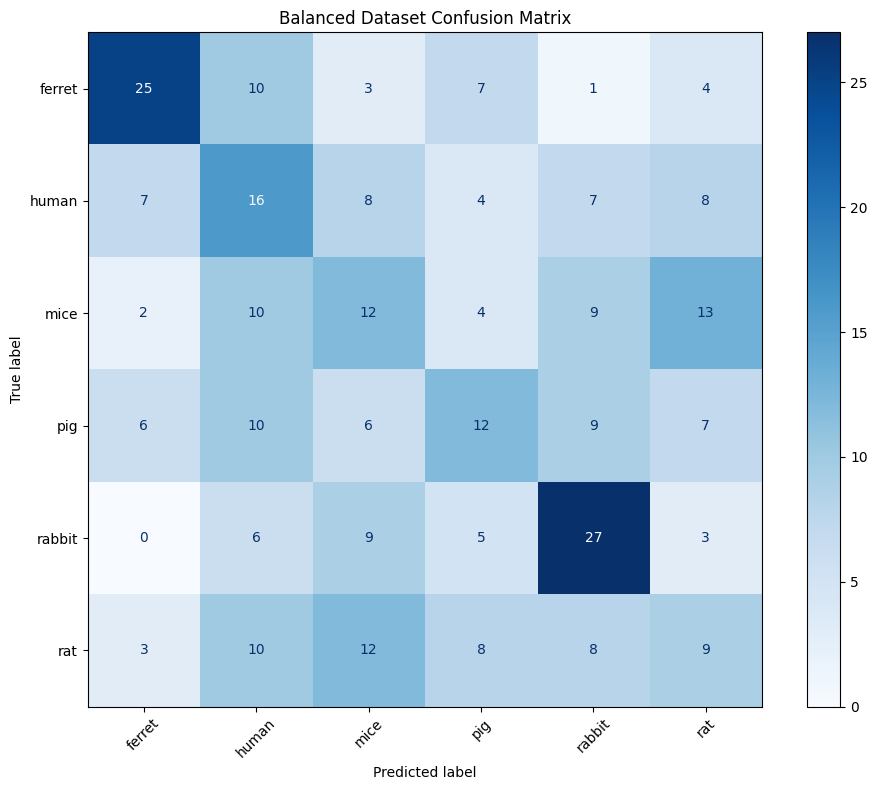

In [152]:
# Overall
overall_balanced = (y_balanced == y_pred_balanced).mean()
print(f"\nOverall accuracy: {overall_balanced:.3f}")

# Confusion matrix
cm_balanced = confusion_matrix(y_balanced, y_pred_balanced)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_balanced, display_labels=species_names)
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('Balanced Dataset Confusion Matrix')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('confusion_matrix_balanced.png', dpi=300)
plt.show()